# 01 - Exploratory data analysis

Descriptive only: associations below are **not** causal or diagnostic claims. All functions live in `src/data/` so the same logic is used by the training pipeline.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from src.config import load_config
cfg = load_config()
M = cfg.path("paths", "metrics_dir"); F = cfg.path("paths", "figures_dir")
pd.set_option("display.precision", 4); pd.set_option("display.width", 200)
def show(name): display(Image(filename=str(F / name)))

In [2]:
from src.data.loader import load_dataset
from src.data.validation import validate_dataframe
df = load_dataset(cfg)
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Schema, dtypes, duplicates, missing values, impossible zeros

In [3]:
rep = validate_dataframe(df, cfg.features, cfg.target, cfg['data']['zero_as_missing'])
print('valid:', rep.is_valid, '| duplicates:', rep.n_duplicate_rows, '| explicit NaN:', sum(rep.explicit_missing.values()))
print('dtypes:', rep.dtypes)
pd.DataFrame({'zeros': rep.zero_counts, 'share': rep.zero_fraction})

valid: True | duplicates: 0 | explicit NaN: 0
dtypes: {'Pregnancies': 'int64', 'Glucose': 'int64', 'BloodPressure': 'int64', 'SkinThickness': 'int64', 'Insulin': 'int64', 'BMI': 'float64', 'DiabetesPedigreeFunction': 'float64', 'Age': 'int64', 'Outcome': 'int64'}


,zeros,share
Glucose,5,0.0065
BloodPressure,35,0.0456
SkinThickness,227,0.2956
Insulin,374,0.4870
BMI,11,0.0143


In [4]:
print('Pregnancies == 0:', (df.Pregnancies == 0).sum(), '(genuine zeros)')
s, i = df.SkinThickness == 0, df.Insulin == 0
print('SkinThickness==0:', s.sum(), '| of which Insulin==0 too:', (s & i).sum())

Pregnancies == 0: 111 (genuine zeros)
SkinThickness==0: 227 | of which Insulin==0 too: 227


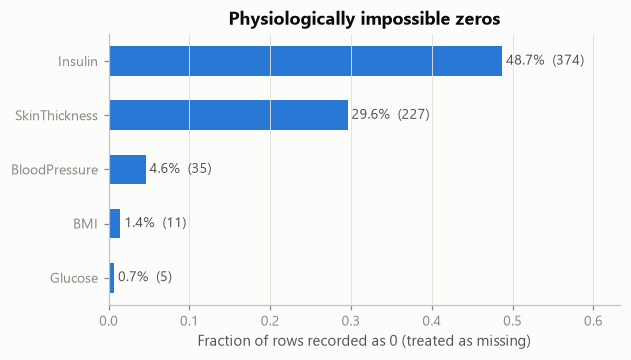

In [5]:
show('eda_missing_zeros.png')

## Target distribution

Outcome
0    500
1    268
Name: count, dtype: int64 0.349


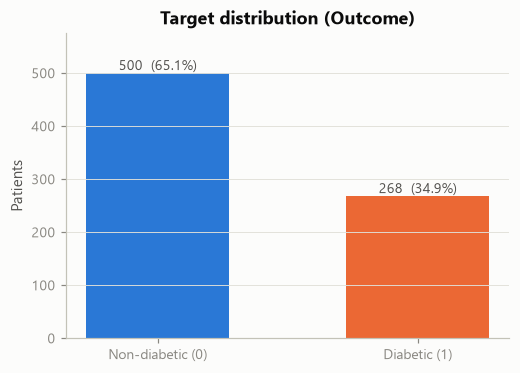

In [6]:
print(df.Outcome.value_counts(), df.Outcome.mean().round(4))
show('eda_target_distribution.png')

## Feature distributions (impossible zeros shown as missing)

In [7]:
from src.data.eda import clean_view, describe_by_class, outlier_summary
clean = clean_view(df, cfg['data']['zero_as_missing'])
clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.8451,3.3696,0.000,1.0000,3.0000,6.0000,17.00
Glucose,763.0,121.6868,30.5356,44.000,99.0000,117.0000,141.0000,199.00
BloodPressure,733.0,72.4052,12.3822,24.000,64.0000,72.0000,80.0000,122.00
SkinThickness,541.0,29.1534,10.4770,7.000,22.0000,29.0000,36.0000,99.00
Insulin,394.0,155.5482,118.7759,14.000,76.2500,125.0000,190.0000,846.00
BMI,757.0,32.4575,6.9250,18.200,27.5000,32.3000,36.6000,67.10
DiabetesPedigreeFunction,768.0,0.4719,0.3313,0.078,0.2437,0.3725,0.6262,2.42
Age,768.0,33.2409,11.7602,21.000,24.0000,29.0000,41.0000,81.00
Outcome,768.0,0.3490,0.4770,0.000,0.0000,0.0000,1.0000,1.00


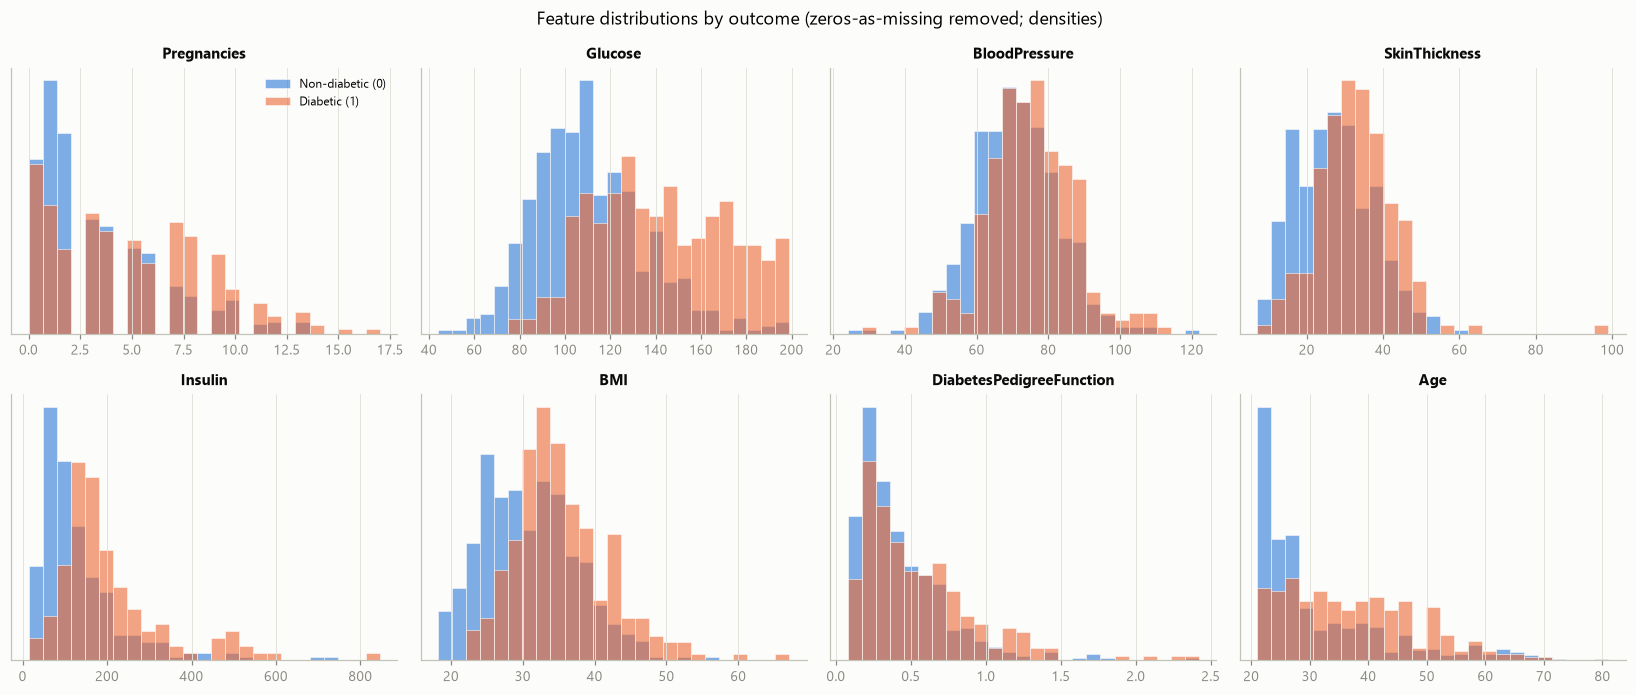

In [8]:
show('eda_histograms_by_class.png')

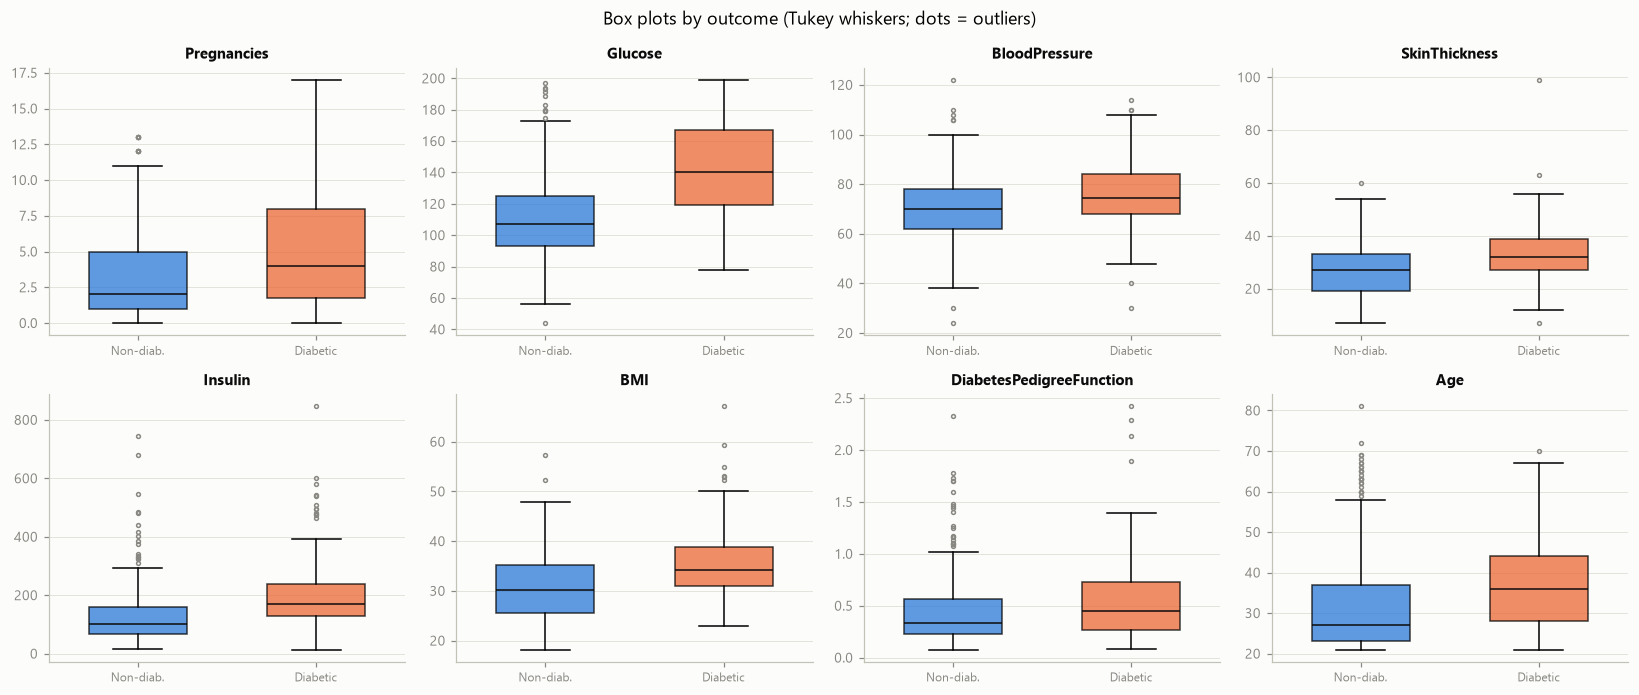

In [9]:
show('eda_boxplots_by_class.png')

## Diabetic vs non-diabetic: effect sizes

Mann-Whitney U test and rank-biserial correlation (positive = higher values among diabetic patients). These quantify *association in this cohort*.

In [10]:
describe_by_class(clean)

,feature,n_non_diabetic,n_diabetic,median_non_diabetic,median_diabetic,iqr_non_diabetic,iqr_diabetic,mann_whitney_p,rank_biserial,point_biserial_r
1,Glucose,497,266,107.000,140.000,93.0-125.0,119.0-167.0,1.3050e-40,0.5856,0.4947
4,Insulin,264,130,102.500,169.500,66.0-161.2,127.5-239.2,7.4770e-14,0.4633,0.3035
5,BMI,491,266,30.100,34.300,25.6-35.3,30.9-38.9,1.8188e-17,0.3741,0.3137
7,Age,500,268,27.000,36.000,23.0-37.0,28.0-44.0,1.1422e-17,0.3739,0.2384
3,SkinThickness,361,180,27.000,32.000,19.0-33.0,27.0-39.0,6.9613e-10,0.3250,0.2595
0,Pregnancies,500,268,2.000,4.000,1.0-5.0,1.8-8.0,3.7451e-08,0.2390,0.2219
2,BloodPressure,481,252,70.000,74.500,62.0-78.0,68.0-84.0,1.6285e-06,0.2152,0.1706
6,DiabetesPedigreeFunction,500,268,0.336,0.449,0.2-0.6,0.3-0.7,1.1966e-06,0.2124,0.1738


## Correlations and pairwise relationships

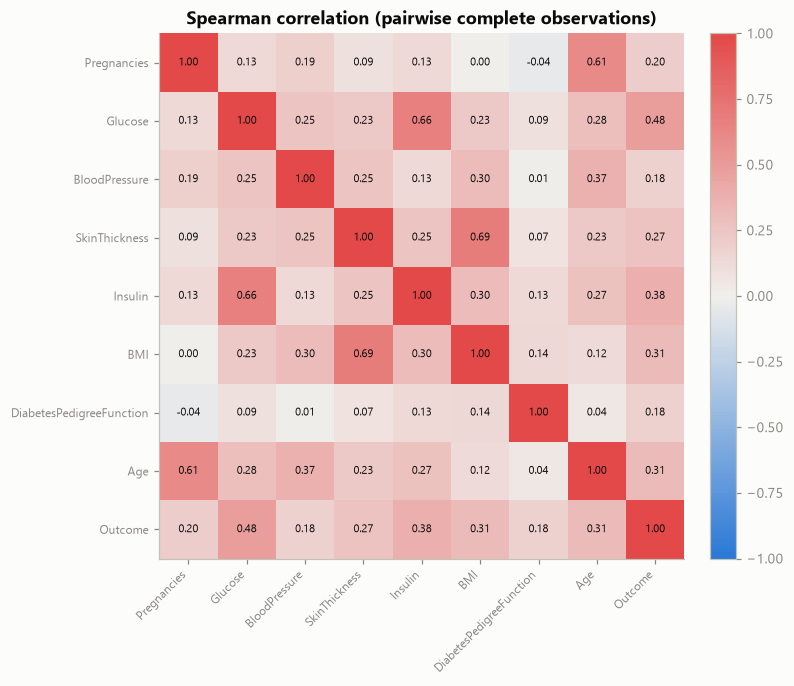

In [11]:
show('eda_correlation_spearman.png')

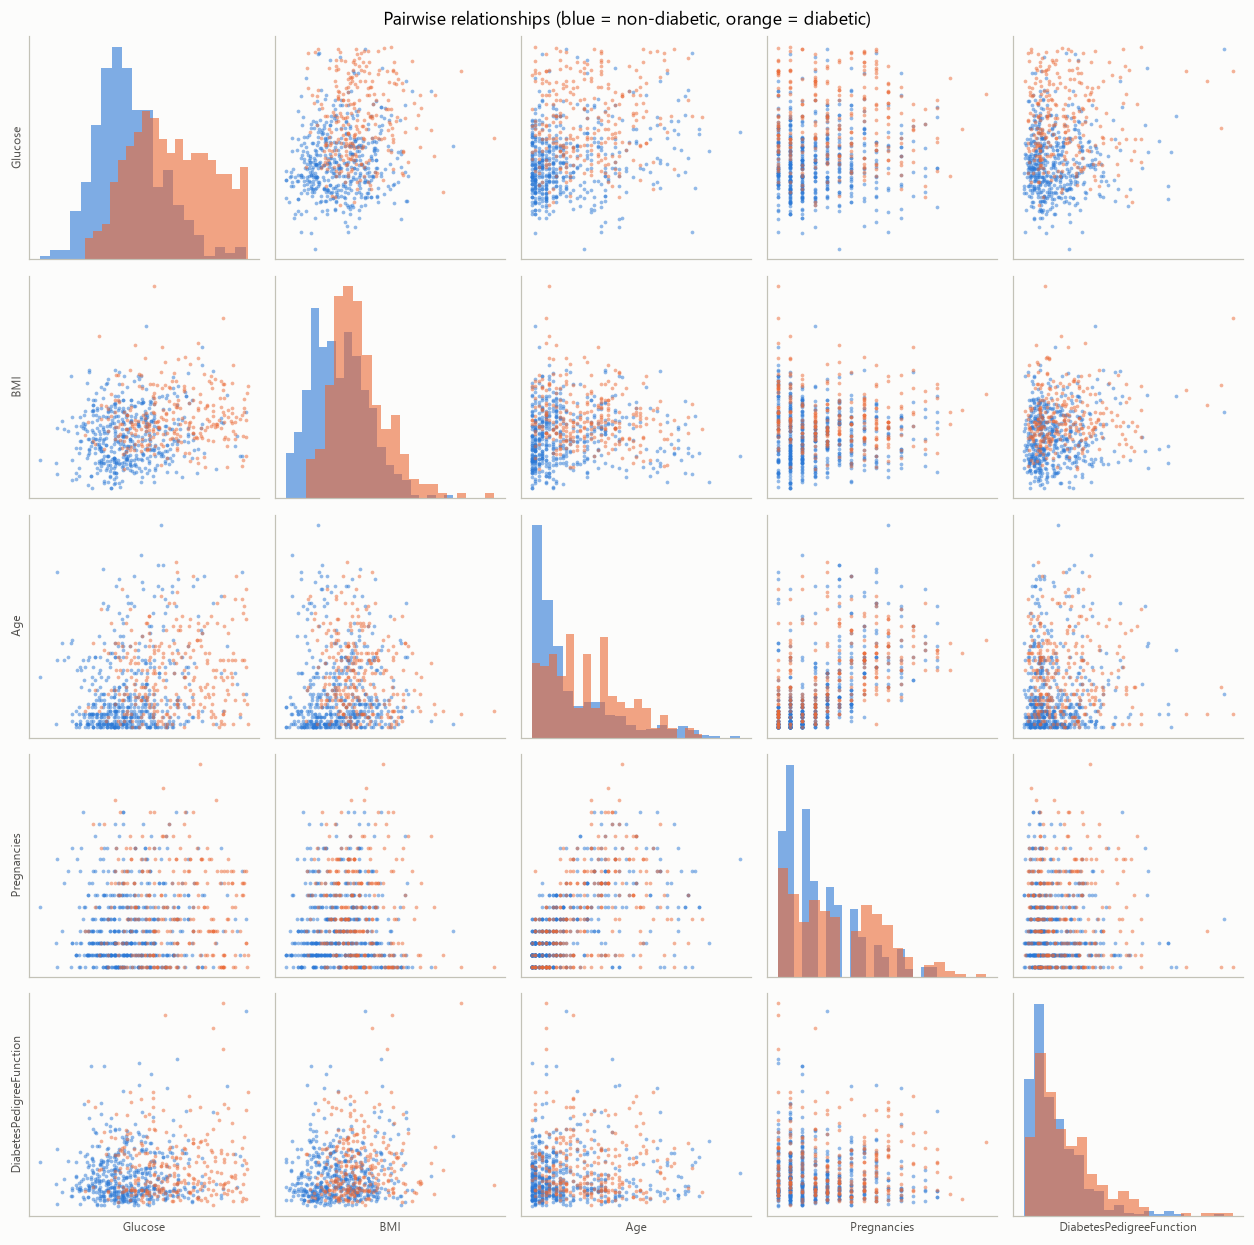

In [12]:
show('eda_pairplot.png')

## Outliers (Tukey fences)

No rows are removed: extreme values (e.g. high insulin) are clinically plausible and tree models are robust to them.

In [13]:
outlier_summary(clean)

,feature,lower_fence,upper_fence,n_low,n_high,min,max
0,Pregnancies,-6.500,13.500,0,4,0.000,17.00
1,Glucose,36.000,204.000,0,0,44.000,199.00
2,BloodPressure,40.000,104.000,4,10,24.000,122.00
3,SkinThickness,1.000,57.000,0,3,7.000,99.00
4,Insulin,-94.375,360.625,0,24,14.000,846.00
5,BMI,13.850,50.250,0,8,18.200,67.10
6,DiabetesPedigreeFunction,-0.330,1.200,0,29,0.078,2.42
7,Age,-1.500,66.500,0,9,21.000,81.00
